In [1]:
import numpy as np
import pandas as pd
import matplotlib as plt

In [2]:
data ='https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [3]:
df = pd.read_csv(data)

In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [6]:
categorical = ['lead_source','industry','employment_status','location']

In [7]:
numerical = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']

In [8]:
df[categorical] = df[categorical].fillna('NA')

In [9]:
df[numerical] = df[numerical].fillna(0.0)

In [10]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [11]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [12]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values


from sklearn.metrics import roc_auc_score,auc

for n in numerical :

    result = roc_auc_score(y_train,df_train[n])
    if result <0.5 :
        result = roc_auc_score(y_train,-df_train[n])
    print(n,round(result,3))

    #it is the lead score


annual_income 0.608
number_of_courses_viewed 0.723
interaction_count 0.765
lead_score 0.788


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

dict_train = df_train[categorical+numerical].to_dict(orient ='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(dict_train)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train,y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [14]:
dict_val = df_val[categorical+numerical].to_dict(orient ='records')
X_val = dv.transform(dict_val)

y_pred = model.predict_proba(X_val)[:,1]
round(roc_auc_score(y_val,y_pred),3)
#0.732

0.732

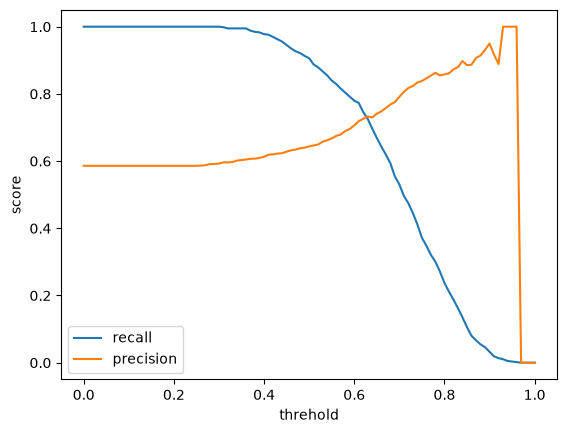

In [15]:
from sklearn.metrics import recall_score , precision_score
import matplotlib.pyplot  as plt
thresholds = np.linspace(0,1,101)
scores = []

for t in thresholds :

    results = (y_pred>= t).astype('int')

    recall = recall_score(y_val,results)
    precision = precision_score(y_val,results , zero_division=0)

    scores.append((t,recall,precision))

columns = ['t','recall','precision']
df_scores = pd.DataFrame(scores,columns=columns)

plt.plot(df_scores['t'],df_scores['recall'],label='recall')

plt.plot(df_scores['t'],df_scores['precision'],label='precision')
plt.xlabel('threhold')
plt.ylabel('score')
plt.legend()

In [16]:
diff = (df_scores.recall - df_scores.precision).abs()
diff = diff[(df_scores.recall>0) | (df_scores.precision>0)] 
df_scores.t[diff.idxmin()]
#0.63

np.float64(0.63)

In [17]:
from sklearn.metrics import recall_score , precision_score
import matplotlib.pyplot  as plt
thresholds = np.linspace(0,1,101)
score = 0
tbest = 0

for t in thresholds :

    results = (y_pred>= t).astype('int')

    recall = recall_score(y_val,results)
    precision = precision_score(y_val,results , zero_division=0)


    if recall + precision == 0:
        continue

    F1score = 2*recall*precision /(recall+precision)
    if score < F1score :
        score = F1score
        tbest = t
   
print(round(tbest,2) , round(F1score,5))
#0.41

0.41 0.00341


In [18]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear',C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [19]:
def predict(df ,dv , model) :
    dicts = df[categorical+numerical].to_dict(orient='records')

    X = dv.transform(dicts)

    y_pred = model.predict_proba(X)[:,1]
    return y_pred

In [20]:
from sklearn.model_selection import KFold
scores2 = []

kfold = KFold(n_splits=5,shuffle=True , random_state=1)
for train_idx , val_idx in kfold.split(df_full_train) :
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv , model = train(df_train,y_train,1.0)
    y_pred = predict(df_val,dv,model)

    auc = roc_auc_score(y_val,y_pred)

    scores2.append(auc)

print(round(np.std(scores2),3))

#0.007

0.007


In [21]:
n_splits = 5

for C in [0.000001, 0.001, 1] : 

    kfold = KFold(n_splits,shuffle=True,random_state=1)

    scores3 = []

    for train_idx , val_idx in kfold.split(df_full_train) :
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv , model = train(df_train,y_train,C)
        y_pred = predict(df_val,dv,model)

        auc = roc_auc_score(y_val,y_pred)

        scores3.append(auc)

    print('C=%s  mean is : %.3f  , std is %.3f '% (C , round(np.mean(scores3),3),round(np.std(scores3),3)))

    #it is 0.001  

C=1e-06  mean is : 0.617  , std is 0.019 
C=0.001  mean is : 0.749  , std is 0.010 
C=1  mean is : 0.732  , std is 0.007 
